<a href="https://colab.research.google.com/github/THE5NEON/Python-Labs/blob/main/%D0%9B%D0%A05_%D0%A2%D0%BE%D1%87%D0%B5%D0%BD%D1%8E%D0%BA_4_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота №5
**Виконав:** Точенюк Ярослав · **Група:** 4-9

Прогнозування часових рядів на основі кліматичних даних.

**Daily Weather Time Series Data - Delhi, India**

https://www.kaggle.com/datasets/yug201/daily-climate-time-series-data-delhi-india?select=kaggel_weather_2013_to_2024.csv

**Тема:** Прогнозування часових рядів на основі кліматичних даних

**Мета роботи:**
Навчитися виконувати аналіз часових рядів, проводити дослідницький аналіз даних (EDA), визначати автокореляційні залежності, будувати моделі прогнозування та оцінювати їхню точність.

**Вихідні дані**

Для виконання роботи використовується датасет Daily Climate Time Series Data (Delhi, India) з платформи Kaggle, який містить щоденні кліматичні показники (температура, вологість, опади тощо) за кілька років.


1. Завантажити датасет з Kaggle.

2. Імпортувати дані у середовище Python (Jupyter Notebook або Google Colab).

3. Ознайомитися зі структурою датасету (head(), info(), describe()).

4. Попередня обробка даних

-Перетворити колонку з датою у формат datetime.

-Відсортувати дані за датою.

-Встановити дату як індекс часового ряду.

-Перевірити наявність пропущених значень та за необхідності обробити їх.

5. Дослідницький аналіз даних (EDA)

-Побудувати графік зміни температури у часі.

-Побудувати ковзне середнє значення температури.

-Побудувати гістограму розподілу температури.

-Побудувати boxplot для виявлення можливих викидів.

-Аналіз автокореляції

Побудувати графік автокореляційної функції (ACF).

Побудувати графік часткової автокореляції (PACF).

-Проаналізувати залежність значень часового ряду від попередніх періодів.

6.Підготовка даних для моделювання

-Розділити дані на тренувальну та тестову вибірки (наприклад, 80% / 20%).

7. Побудувати щонайменше три моделі прогнозування:

-ARIMA (класична статистична модель);

-Prophet (модель прогнозування часових рядів від Meta);

-LSTM (нейронна мережа для послідовних даних).

8. Оцінка моделей
Для кожної моделі обчислити метрики:

-MAE (Mean Absolute Error)

-RMSE (Root Mean Squared Error)

-MAPE (Mean Absolute Percentage Error)

8.Візуалізація результатів

-Побудувати графіки прогнозованих та фактичних значень.

-Побудувати порівняльний графік прогнозів усіх моделей.

-Порівняння моделей

-Створити таблицю з метриками точності.

9.Визначити модель, яка показала найкращий результат.

In [1]:
import importlib.util, subprocess, sys
for package in ['kagglehub', 'prophet']:
    if importlib.util.find_spec(package) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', package])
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import acf, pacf
from prophet import Prophet
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
import kagglehub
np.random.seed(42)
torch.manual_seed(42)
plt.style.use('seaborn-v0_8-whitegrid')


In [2]:
filename = 'kaggel_weather_2013_to_2024.csv'
local = Path(filename)
if local.exists():
    csv_path = local
else:
    folder = Path(kagglehub.dataset_download('yug201/daily-climate-time-series-data-delhi-india'))
    matches = list(folder.rglob(filename))
    if not matches:
        raise FileNotFoundError(f'Не знайдено {filename} у {folder}')
    csv_path = matches[0]
print(csv_path)

Using Colab cache for faster access to the 'daily-climate-time-series-data-delhi-india' dataset.
/kaggle/input/daily-climate-time-series-data-delhi-india/kaggel_weather_2013_to_2024.csv


In [3]:
raw = pd.read_csv(csv_path)
print('Розмір:', raw.shape)
display(raw.head())
raw.info()
display(raw.describe(include='all'))

Розмір: (3557, 29)


,Unnamed: 0,DATE,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
0,0,4/14/2013,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
1,1,4/15/2013,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2,2,4/16/2013,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
3,3,4/17/2013,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
4,4,4/18/2013,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3557 entries, 0 to 3556
Data columns (total 29 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Unnamed: 0             3557 non-null   int64  
 1   DATE                   3557 non-null   object 
 2   tempmax                3557 non-null   float64
 3   tempmin                3557 non-null   float64
 4   temp                   3557 non-null   float64
 5   feelslikemax           3557 non-null   float64
 6   feelslikemin           3557 non-null   float64
 7   feelslike              3557 non-null   float64
 8   humidity               3557 non-null   float64
 9   precip                 3557 non-null   float64
 10  precipprob             3557 non-null   int64  
 11  precipcover            3557 non-null   float64
 12  windspeed              3557 non-null   float64
 13  sealevelpressure       3557 non-null   float64
 14  conditions             3557 non-null   object 
 15  Year

,Unnamed: 0,DATE,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
count,3557.000000,3557,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,...,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000
unique,NaN,3556,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,5/1/2022,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,1778.000000,NaN,31.367501,20.076132,25.403374,34.280180,20.938769,27.306803,63.755440,2.459033,...,19.269328,26.865898,1919.095583,1240.914352,1554.375926,2137.701105,1299.951985,1696.889528,11.291369,195.577670
std,1026.961781,NaN,7.073934,7.568531,7.325541,9.651743,9.004827,9.301636,18.129251,10.636255,...,3.219299,14.910296,525.888218,580.706647,539.222716,839.862724,692.599628,754.644547,3.622231,55.583693
min,0.000000,NaN,9.100000,2.000000,6.500000,7.900000,0.300000,5.700000,16.100000,0.000000,...,13.000000,1.000000,686.400000,181.200000,586.560000,636.480000,18.960000,560.880000,1.500000,73.465023
25%,889.000000,NaN,26.400000,13.000000,19.100000,26.300000,13.000000,19.100000,53.000000,0.000000,...,17.000000,14.000000,1541.550000,759.360000,1119.820000,1534.400000,752.070000,1113.600000,8.300000,164.445621
50%,1778.000000,NaN,33.000000,22.000000,27.700000,35.400000,22.000000,28.400000,65.800000,0.000000,...,20.000000,27.000000,1823.360000,1078.400000,1420.200000,1845.510000,1080.320000,1422.960000,11.600000,180.548686
75%,2667.000000,NaN,36.000000,26.900000,31.000000,42.700000,28.000000,35.400000,76.900000,0.000000,...,22.000000,40.000000,2341.170000,1752.400000,2035.800000,2764.200000,1864.200000,2314.620000,14.100000,233.676622


Підготовка даних

In [4]:
import re
cols = {re.sub(r'[^a-z0-9]', '', str(c).lower()): c for c in raw.columns}
date_col = next((cols[k] for k in ['date','datetime','time','day'] if k in cols), None)
temp_col = next((cols[k] for k in ['meantemp','tavg','avgtemp','temperature','temp','temperaturemean','meantemperature','averagetemperature','temperature2mmean','tempavg','tmean','avgtemperature','temperatureavg','temperaturec','tempmean','t2m','temperature2m'] if k in cols), None)
if temp_col is None:
    temp_col = next((c for k,c in cols.items() if ('temp' in k and any(s in k for s in ['mean','avg','average']))), None)
if date_col is None or temp_col is None:
    raise ValueError(f'Не знайдено дату або середню температуру. Колонки: {list(raw.columns)}')
df = raw[[date_col,temp_col]].copy()
df.columns = ['DATE','temperature']
df['DATE'] = pd.to_datetime(df['DATE'], errors='coerce').dt.normalize()
df['temperature'] = pd.to_numeric(df['temperature'], errors='coerce')
df = df.dropna(subset=['DATE']).groupby('DATE').mean().sort_index().asfreq('D')
print('Колонка температури:', temp_col)
print('Період:', df.index.min(), '—', df.index.max())

Колонка температури: temp
Період: 2013-04-14 00:00:00 — 2024-11-30 00:00:00


In [5]:
df.info()
display(df.head())
display(df.describe())

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 4249 entries, 2013-04-14 to 2024-11-30
Freq: D
Data columns (total 1 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   temperature  3556 non-null   float64
dtypes: float64(1)
memory usage: 66.4 KB


,temperature
DATE,
2013-04-14,28.7
2013-04-15,28.6
2013-04-16,31.7
2013-04-17,29.9
2013-04-18,30.6


,temperature
count,3556.000000
mean,25.400984
std,7.325185
min,6.500000
25%,19.100000
50%,27.700000
75%,31.000000
max,39.500000


In [6]:
print('Пропуски до обробки:', df.isna().sum())
df = df.ffill().dropna()
print('Пропуски після обробки:', df.isna().sum())
assert len(df) > 100 and df.index.is_monotonic_increasing and df.index.is_unique

Пропуски до обробки: temperature    693
dtype: int64
Пропуски після обробки: temperature    0
dtype: int64


Графік температури

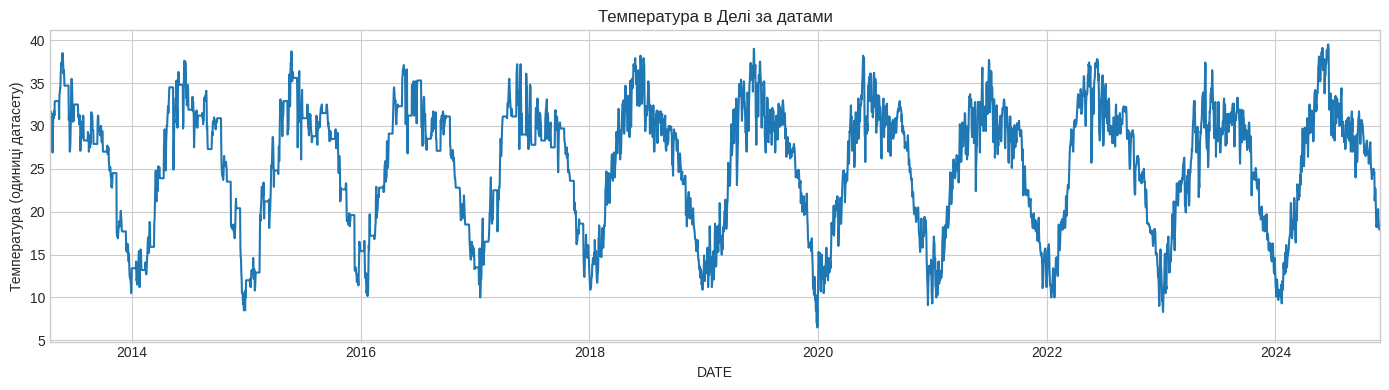

In [7]:
df.temperature.plot(figsize=(14,4), title='Температура в Делі за датами', ylabel='Температура (одиниці датасету)')
plt.tight_layout(); plt.show()

Ковзне середнє

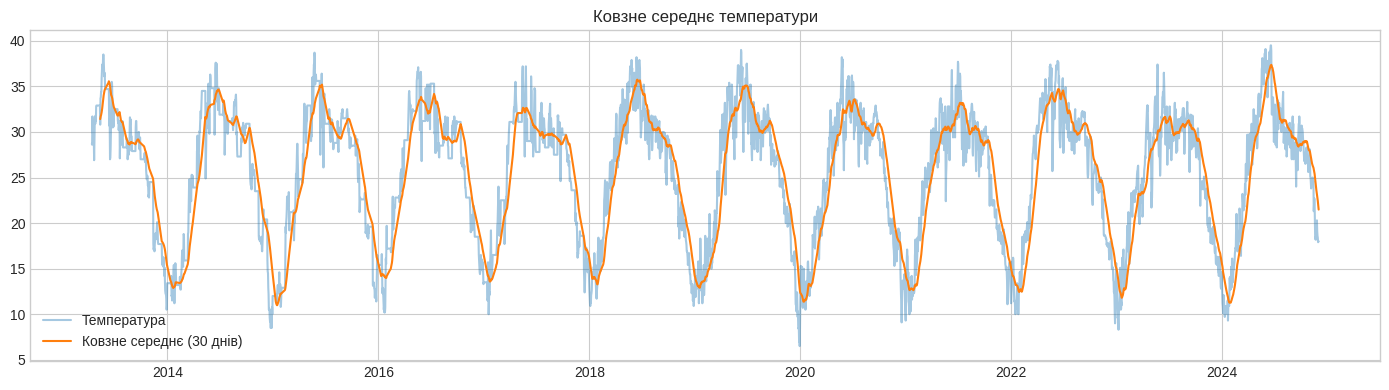

In [8]:
plt.figure(figsize=(14,4))
plt.plot(df.index, df.temperature, alpha=.4, label='Температура')
plt.plot(df.index, df.temperature.rolling(30).mean(), label='Ковзне середнє (30 днів)')
plt.legend(); plt.title('Ковзне середнє температури'); plt.tight_layout(); plt.show()

Розподіл температури

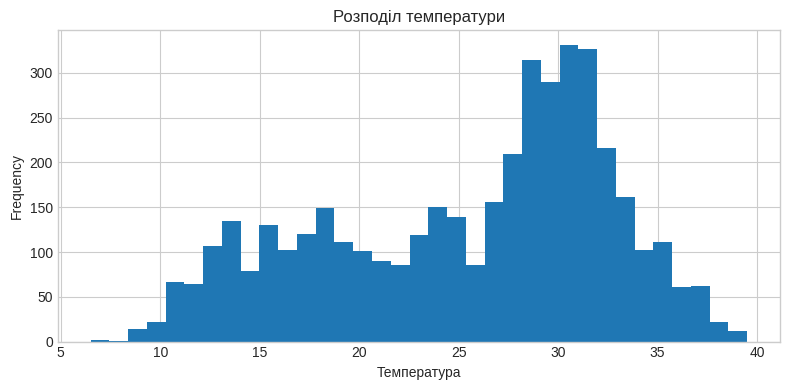

In [9]:
df.temperature.plot.hist(bins=35, figsize=(8,4), title='Розподіл температури')
plt.xlabel('Температура'); plt.tight_layout(); plt.show()

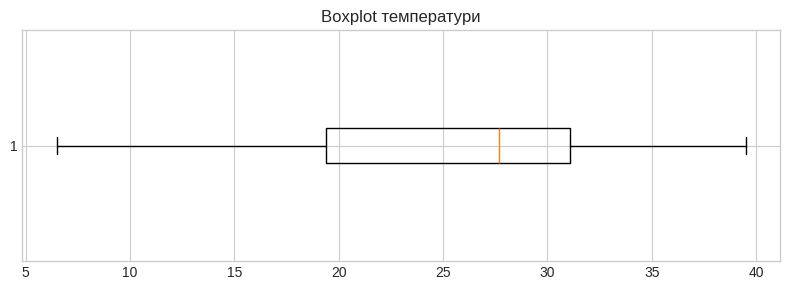

Потенційні викиди за IQR: 0


In [10]:
plt.figure(figsize=(8,3)); plt.boxplot(df.temperature, vert=False)
plt.title('Boxplot температури'); plt.tight_layout(); plt.show()
q1,q3 = df.temperature.quantile([.25,.75]); iqr=q3-q1
print('Потенційні викиди за IQR:', ((df.temperature<q1-1.5*iqr)|(df.temperature>q3+1.5*iqr)).sum())

Аналіз автокореляції
ACF

PACF

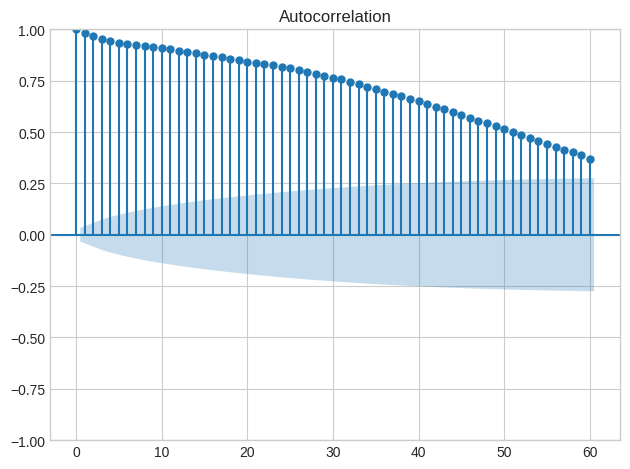

In [11]:
eda_train = df.temperature.iloc[:int(len(df)*.8)]
plot_acf(eda_train, lags=min(60,len(eda_train)//2-1)); plt.tight_layout(); plt.show()

Автокореляційна функція (ACF) використовується для аналізу залежності значень часового ряду від його попередніх значень. Вона відображає ступінь кореляції між значенням показника у певний момент часу та значеннями цього самого показника у попередні моменти часу, які називаються лагами. Побудова графіка автокореляційної функції дозволяє виявити, чи існує статистично значуща залежність між поточним значенням ряду та його попередніми спостереженнями. На такому графіку по горизонтальній осі відкладаються лаги, тобто кількість часових кроків назад, а по вертикальній — значення коефіцієнта автокореляції. Аналіз графіка ACF дає можливість виявити наявність тренду, сезонності або інших закономірностей у часовому ряді, а також використовується для визначення параметрів статистичних моделей прогнозування, зокрема моделі ARIMA.

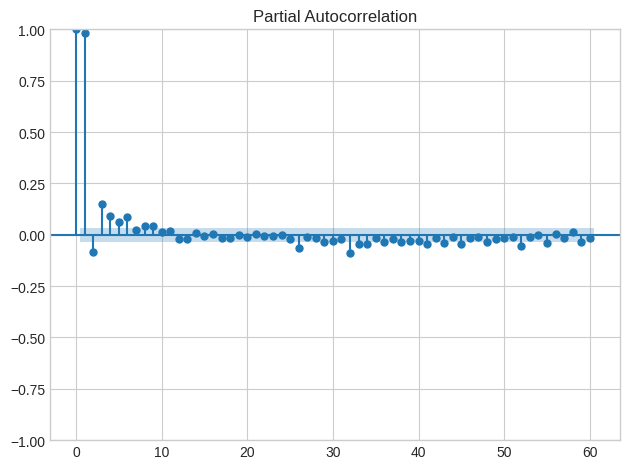

ACF лаг 1: 0.984
PACF лаг 1: 0.984
Додатні значення вказують на позитивну залежність від попередніх спостережень; значущість оцінюємо за довірчими межами графіків.


In [12]:
plot_pacf(eda_train, lags=min(60,len(eda_train)//2-1), method='ywm'); plt.tight_layout(); plt.show()
print('ACF лаг 1:', round(acf(eda_train,nlags=1)[1],3))
print('PACF лаг 1:', round(pacf(eda_train,nlags=1,method='ywm')[1],3))
print('Додатні значення вказують на позитивну залежність від попередніх спостережень; значущість оцінюємо за довірчими межами графіків.')

Часткова автокореляційна функція (PACF) застосовується для більш точного визначення залежності між значеннями часового ряду. На відміну від звичайної автокореляційної функції, PACF вимірює кореляцію між значенням ряду у певний момент часу та значенням у попередній момент часу з конкретним лагом, усуваючи вплив усіх проміжних лагів. Таким чином, часткова автокореляція показує «чисту» залежність між двома спостереженнями часового ряду. Побудова графіка PACF дозволяє визначити, які саме лаги мають статистично значущий вплив на значення ряду. Це є важливим етапом під час побудови моделей прогнозування часових рядів, оскільки аналіз графіка часткової автокореляції використовується для визначення порядку авторегресійної складової моделі, зокрема параметра
𝑝
p у моделі ARIMA.

In [13]:
series = df.temperature.astype(float)
cut = int(len(series)*.8)
train, test = series.iloc[:cut], series.iloc[cut:]
assert train.index.max() < test.index.min()
print('Train:', len(train), 'Test:', len(test))

Train: 3399 Test: 850


ARIMA

https://developer.ibm.com/tutorials/awb-arima-models-in-python/

In [14]:
fits = {}
for order in [(1,0,1),(2,0,1),(1,1,1),(2,1,2)]:
    fits[order] = ARIMA(train, order=order).fit()
best_order = min(fits, key=lambda k: fits[k].aic)
arima = fits[best_order]
print('Порядок:', best_order)
pred_arima = pd.Series(np.asarray(arima.forecast(steps=len(test))), index=test.index)

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


Порядок: (2, 1, 2)


In [15]:
print(arima.summary())

                               SARIMAX Results                                
Dep. Variable:            temperature   No. Observations:                 3399
Model:                 ARIMA(2, 1, 2)   Log Likelihood               -5602.607
Date:                Tue, 24 Nov 2026   AIC                          11215.214
Time:                        16:03:41   BIC                          11245.869
Sample:                    04-14-2013   HQIC                         11226.171
                         - 08-03-2022                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.7279      0.075      9.731      0.000       0.581       0.875
ar.L2         -0.1519      0.069     -2.190      0.029      -0.288      -0.016
ma.L1         -0.6732      0.076     -8.903      0.0

сигма 2 : це представляє дисперсію залишкових значень, чим менше, тим краще

логарифмічна правдоподібність : це оцінка максимальної правдоподібності для моделі ARIMA, чим вище, тим краще

aic : міра ступеню відповідності та економності моделі, чим нижче, тим краще

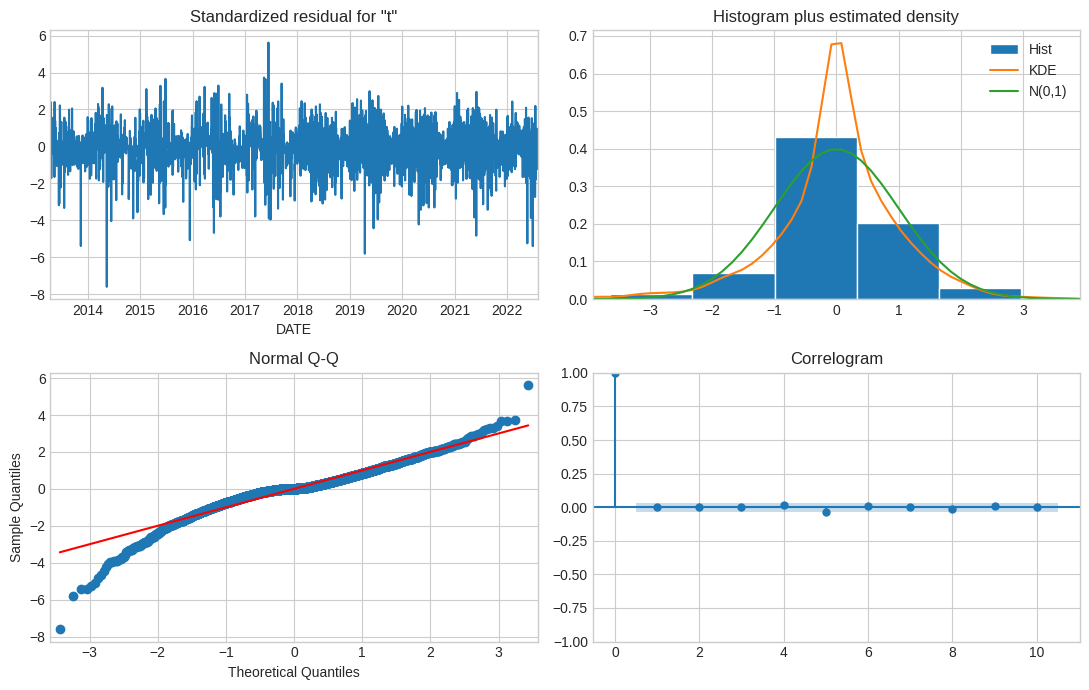

Середнє залишків: 0.009019422375604765


In [16]:
arima.plot_diagnostics(figsize=(11,7)); plt.tight_layout(); plt.show()
print('Середнє залишків:', arima.resid.mean())

In [17]:
def metrics(actual, predicted):
    assert actual.index.equals(predicted.index)
    a,p = np.asarray(actual),np.asarray(predicted)
    assert np.isfinite(a).all() and np.isfinite(p).all()
    mask = np.abs(a)>1e-8
    return {'MAE': mean_absolute_error(a,p), 'RMSE': np.sqrt(mean_squared_error(a,p)), 'MAPE (%)': np.mean(np.abs((a[mask]-p[mask])/a[mask]))*100 if mask.any() else np.nan}
results = {'ARIMA':metrics(test,pred_arima)}
print(results['ARIMA'])
def plot_prediction(pred, name):
    plt.figure(figsize=(13,4)); plt.plot(test.index,test,label='Фактичні'); plt.plot(pred.index,pred,label=name); plt.legend(); plt.title(name); plt.tight_layout(); plt.show()

{'MAE': 6.201521070844471, 'RMSE': np.float64(8.411355870148624), 'MAPE (%)': np.float64(35.82700849085642)}


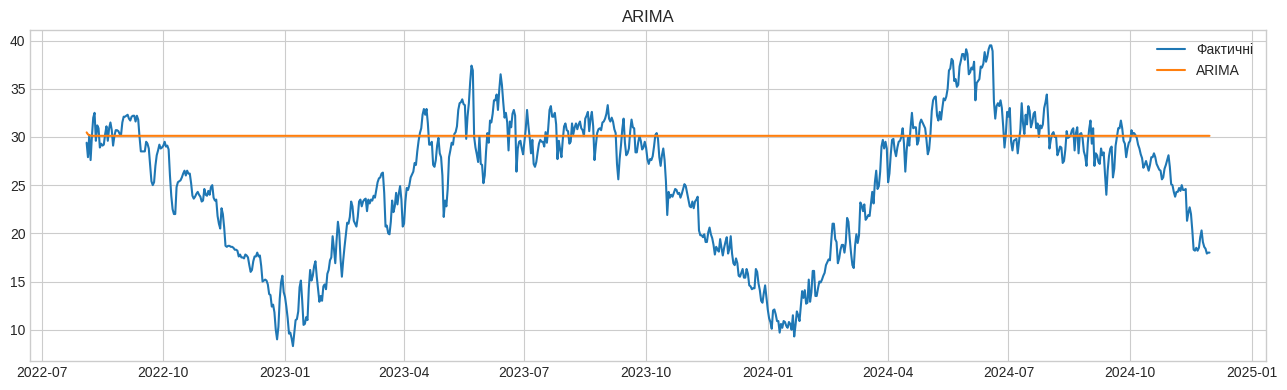

In [18]:
plot_prediction(pred_arima,'ARIMA')

PROPHET

https://facebook.github.io/prophet/docs/quick_start.html

In [19]:
prophet_train = train.rename('y').rename_axis('ds').reset_index()
display(prophet_train.head())

,ds,y
0,2013-04-14,28.7
1,2013-04-15,28.6
2,2013-04-16,31.7
3,2013-04-17,29.9
4,2013-04-18,30.6


In [20]:
prophet_model = Prophet(yearly_seasonality=True, weekly_seasonality=True, daily_seasonality=False)
prophet_model.fit(prophet_train)

Прогноз

In [21]:
forecast = prophet_model.predict(pd.DataFrame({'ds':test.index}))
pred_prophet = pd.Series(forecast.yhat.to_numpy(), index=test.index)

In [22]:
results['Prophet'] = metrics(test,pred_prophet)
print(results['Prophet'])

{'MAE': 2.0460176531968286, 'RMSE': np.float64(2.6146425426476925), 'MAPE (%)': np.float64(9.260635774112421)}


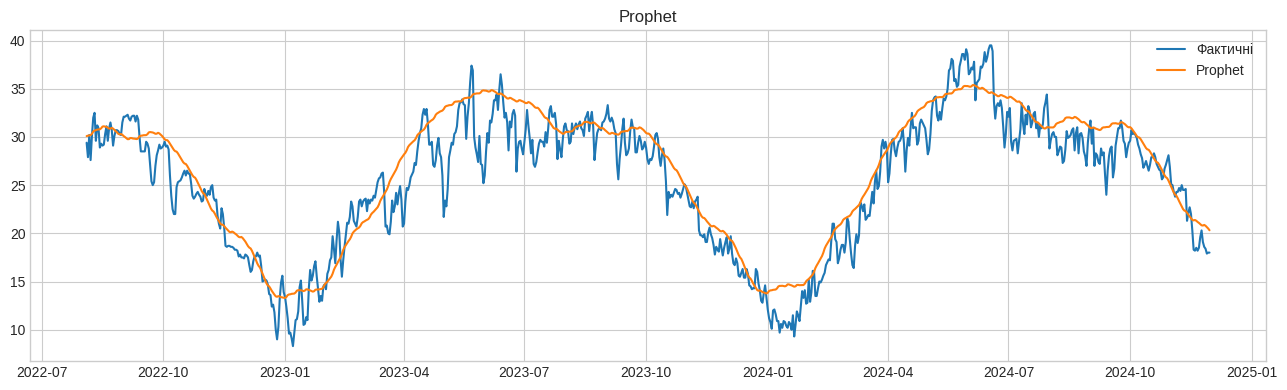

In [23]:
plot_prediction(pred_prophet,'Prophet')

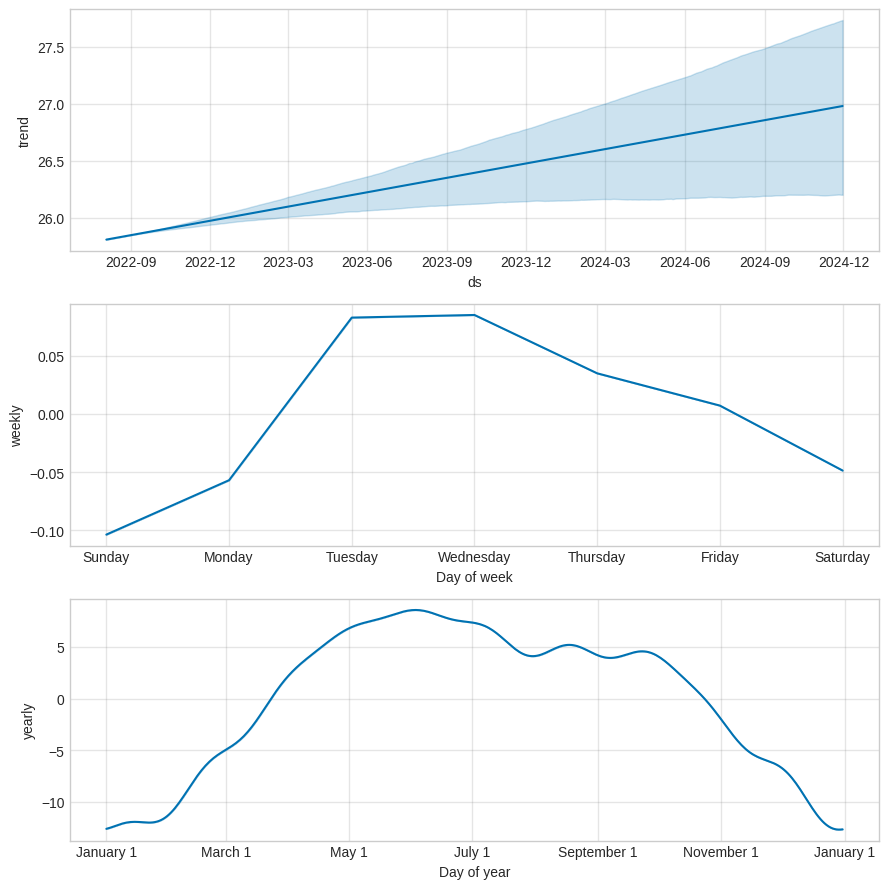

In [24]:
prophet_model.plot_components(forecast); plt.show()

ПІДГОТОВКА ДАНИХ ДЛЯ LSTM

In [25]:
lookback = 30
scaler = MinMaxScaler()
scaled_train = scaler.fit_transform(train.to_numpy().reshape(-1,1)).astype('float32')
scaled_all = scaler.transform(series.to_numpy().reshape(-1,1)).astype('float32')
X = np.stack([scaled_all[i-lookback:i] for i in range(lookback,len(series))])
y = scaled_all[lookback:]

In [26]:
n_train = len(train)-lookback
X_train,y_train = X[:n_train],y[:n_train]
X_test,y_test = X[n_train:],y[n_train:]
assert len(X_test)==len(test)
print(X_train.shape,X_test.shape)

(3369, 30, 1) (850, 30, 1)


In [27]:
class TemperatureLSTM(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=32, batch_first=True)
        self.out = nn.Linear(32,1)
    def forward(self,x):
        seq,_ = self.lstm(x)
        return self.out(seq[:,-1,:])
torch.set_num_threads(2)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = TemperatureLSTM().to(device)
optimizer = torch.optim.Adam(model.parameters(),lr=.001)
criterion = nn.MSELoss()

Epoch 5: 0.005261
Epoch 10: 0.004279
Epoch 15: 0.003734
Epoch 20: 0.003368


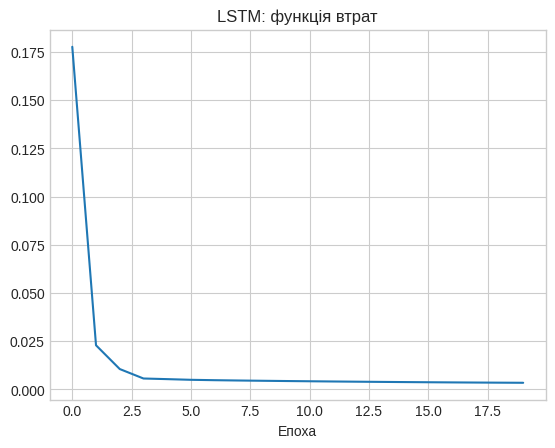

In [28]:
loader = DataLoader(TensorDataset(torch.from_numpy(X_train),torch.from_numpy(y_train)),batch_size=64,shuffle=False)
losses=[]
for epoch in range(20):
    model.train(); total=0
    for xb,yb in loader:
        xb,yb=xb.to(device),yb.to(device)
        optimizer.zero_grad(); loss=criterion(model(xb),yb); loss.backward(); optimizer.step()
        total += loss.item()*len(xb)
    losses.append(total/len(X_train))
    if (epoch+1)%5==0: print(f'Epoch {epoch+1}: {losses[-1]:.6f}')
plt.plot(losses); plt.title('LSTM: функція втрат'); plt.xlabel('Епоха'); plt.show()

In [29]:
print(model)
print('Кількість параметрів:',sum(p.numel() for p in model.parameters()))

TemperatureLSTM(
  (lstm): LSTM(1, 32, batch_first=True)
  (out): Linear(in_features=32, out_features=1, bias=True)
)
Кількість параметрів: 4513


In [30]:
window = scaled_train[-lookback:].copy(); lstm_scaled=[]
model.eval()
with torch.no_grad():
    for _ in range(len(test)):
        value = model(torch.from_numpy(window[None]).to(device)).item()
        lstm_scaled.append(value)
        window = np.concatenate([window[1:],np.array([[value]],dtype='float32')])
lstm_values = scaler.inverse_transform(np.array(lstm_scaled).reshape(-1,1)).ravel()

In [31]:
pred_lstm = pd.Series(lstm_values,index=test.index)
assert pred_lstm.index.equals(test.index)
display(pred_lstm.head())

,0
DATE,
2022-08-04,29.807116
2022-08-05,29.930583
2022-08-06,30.024207
2022-08-07,30.103687
2022-08-08,30.174877


In [32]:
results['LSTM'] = metrics(test,pred_lstm)
print(results['LSTM'])

{'MAE': 7.402672856751611, 'RMSE': np.float64(9.713800631240732), 'MAPE (%)': np.float64(42.225685688573044)}


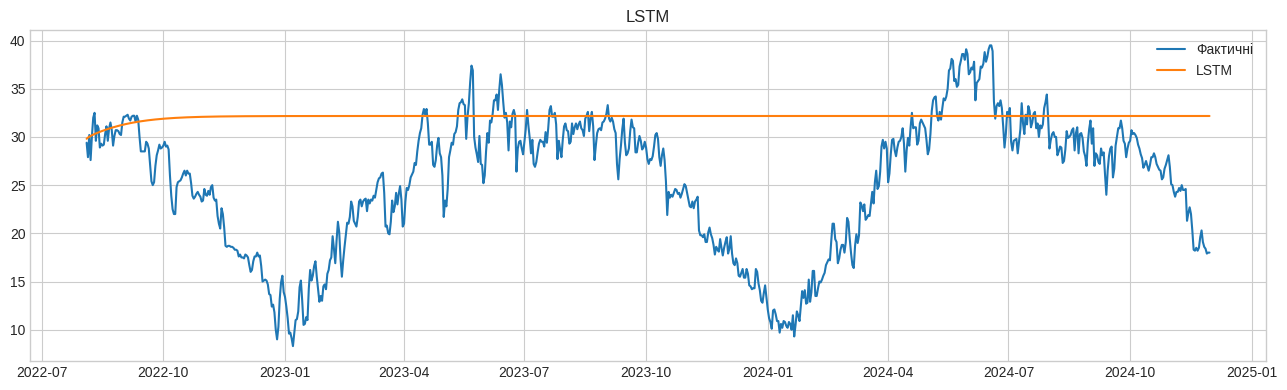

In [33]:
plot_prediction(pred_lstm,'LSTM')

Порівняння моделей

,MAE,RMSE,MAPE (%)
Prophet,2.046,2.615,9.261
ARIMA,6.202,8.411,35.827
LSTM,7.403,9.714,42.226


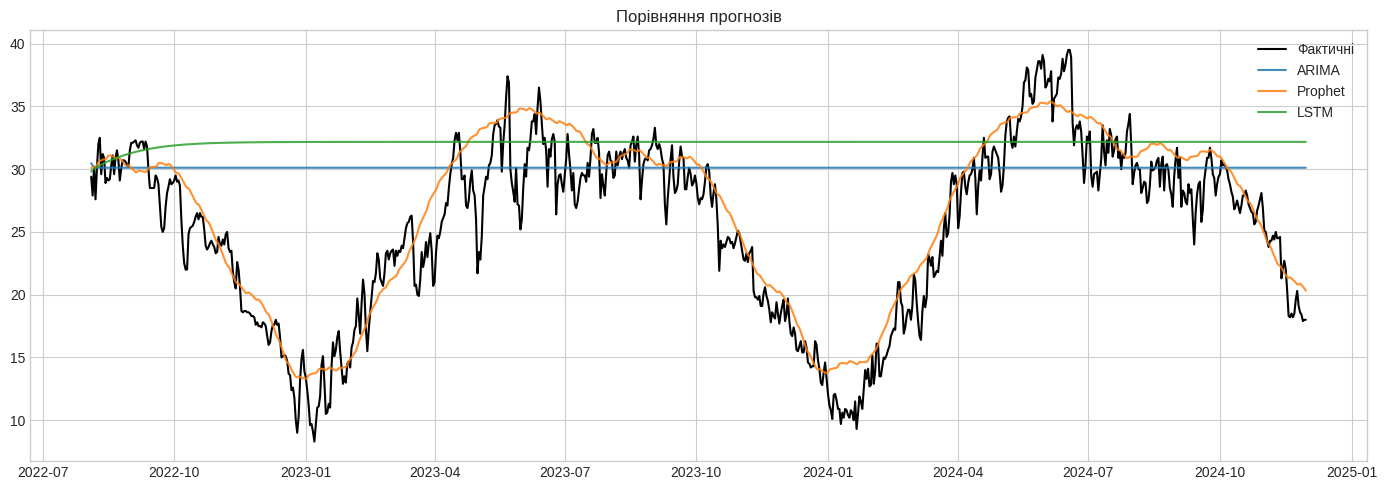

Найкраща за RMSE: Prophet
Найкраща за MAE: Prophet
Найкраща за MAPE: Prophet


In [34]:
comparison = pd.DataFrame(results).T.sort_values('RMSE')
display(comparison.round(3))
plt.figure(figsize=(14,5)); plt.plot(test.index,test,label='Фактичні',color='black')
for name,pred in [('ARIMA',pred_arima),('Prophet',pred_prophet),('LSTM',pred_lstm)]:
    plt.plot(pred.index,pred,label=name,alpha=.85)
plt.legend(); plt.title('Порівняння прогнозів'); plt.tight_layout(); plt.show()
print('Найкраща за RMSE:',comparison.index[0])
print('Найкраща за MAE:',comparison.MAE.idxmin())
print('Найкраща за MAPE:',comparison['MAPE (%)'].idxmin())

## Висновок

Сформулюйте висновок за результатами роботи: коротко охарактеризуйте виконаний аналіз, порівняйте моделі ARIMA, Prophet та LSTM за метриками MAE, RMSE і MAPE та зазначте, яка модель продемонструвала найкращу якість прогнозування.


In [35]:
best = comparison.index[0]
print(f'Виконано EDA, ACF/PACF і хронологічний поділ 80/20. Навчено ARIMA, Prophet та LSTM. Найкраща за RMSE модель: {best}.')
print(f"Її MAE = {comparison.loc[best,'MAE']:.3f}, RMSE = {comparison.loc[best,'RMSE']:.3f}, MAPE = {comparison.loc[best,'MAPE (%)']:.3f}%. Моделі порівняно на однаковому тестовому горизонті без доступу до фактичних майбутніх температур.")

Виконано EDA, ACF/PACF і хронологічний поділ 80/20. Навчено ARIMA, Prophet та LSTM. Найкраща за RMSE модель: Prophet.
Її MAE = 2.046, RMSE = 2.615, MAPE = 9.261%. Моделі порівняно на однаковому тестовому горизонті без доступу до фактичних майбутніх температур.
